# 04 – Fraud Detection with Machine Learning

## Project Overview

This notebook develops and evaluates machine learning models to identify fraudulent transactions in the PaySim synthetic financial dataset.

The main challenge is the severe class imbalance: fraudulent transactions account for approximately 0.1291% of the dataset.

## Objectives

- Prepare transaction data for machine learning.
- Identify relevant features and prevent data leakage.
- Split the dataset into training and test sets.
- Train a baseline classification model.
- Evaluate performance using precision, recall, F1-score, and the confusion matrix.
- Interpret the results and discuss model limitations.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File paths
from pathlib import Path

In [2]:
# Define the path to the validated dataset
file_path = Path("../data/processed/paysim_validated.csv")

# Check that the dataset exists
assert file_path.exists(), f"File not found: {file_path}"

# Load the validated dataset
df = pd.read_csv(file_path)

# Display dataset dimensions
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 6,362,620
Columns: 11


In [3]:
# Display column names and data types
df.dtypes

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

In [4]:
# Select features available before or at transaction initiation
feature_columns = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

# Define features and target
X = df[feature_columns].copy()
y = df["isFraud"].copy()

# Inspect selected features
X.head()

,step,type,amount,oldbalanceOrg,oldbalanceDest
0,1,PAYMENT,9839.64,170136.0,0.0
1,1,PAYMENT,1864.28,21249.0,0.0
2,1,TRANSFER,181.00,181.0,0.0
3,1,CASH_OUT,181.00,181.0,21182.0
4,1,PAYMENT,11668.14,41554.0,0.0


In [5]:
# Count legitimate and fraudulent transactions
class_counts = y.value_counts().sort_index()

# Calculate class percentages
class_percentages = y.value_counts(normalize=True).sort_index() * 100

# Display class distribution
class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages
})

class_distribution

,Count,Percentage
isFraud,,
0,6354407,99.870918
1,8213,0.129082


In [6]:
# Define the temporal split at 80% of the simulation period
split_step = int(df["step"].max() * 0.8)

# Create chronological training and test sets
train_mask = df["step"] <= split_step
test_mask = df["step"] > split_step

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

# Display dataset sizes and fraud counts
print(f"Training transactions: {len(X_train):,}")
print(f"Test transactions: {len(X_test):,}")
print(f"Training frauds: {y_train.sum():,}")
print(f"Test frauds: {y_test.sum():,}")

Training transactions: 6,239,040
Test transactions: 123,580
Training frauds: 6,559
Test frauds: 1,654


In [7]:
# Apply one-hot encoding to transaction types
X_train_encoded = pd.get_dummies(
    X_train,
    columns=["type"],
    dtype=int
)

X_test_encoded = pd.get_dummies(
    X_test,
    columns=["type"],
    dtype=int
)

# Align test columns with training columns
X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# Display the encoded features
X_train_encoded.head()

,step,amount,oldbalanceOrg,oldbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,0.0,0,0,0,1,0
1,1,1864.28,21249.0,0.0,0,0,0,1,0
2,1,181.00,181.0,0.0,0,0,0,0,1
3,1,181.00,181.0,21182.0,0,1,0,0,0
4,1,11668.14,41554.0,0.0,0,0,0,1,0


In [8]:
# Check encoded dataset dimensions
print(f"Training shape: {X_train_encoded.shape}")
print(f"Test shape: {X_test_encoded.shape}")

# Verify that feature columns match
print(
    "Matching columns:",
    X_train_encoded.columns.equals(X_test_encoded.columns)
)

Training shape: (6239040, 9)
Test shape: (123580, 9)
Matching columns: True


In [9]:
# Import the logistic regression classifier
from sklearn.linear_model import LogisticRegression

# Import the feature scaling utility
from sklearn.preprocessing import StandardScaler

In [10]:
# Select continuous numerical features
numeric_features = [
    "step",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest"
]

# Initialize the scaler
scaler = StandardScaler()

# Create copies to preserve the original encoded datasets
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

# Fit the scaler on training data only
X_train_scaled[numeric_features] = scaler.fit_transform(
    X_train_encoded[numeric_features]
)

# Apply the same transformation to test data
X_test_scaled[numeric_features] = scaler.transform(
    X_test_encoded[numeric_features]
)

# Display the standardized training features
X_train_scaled.head()

,step,amount,oldbalanceOrg,oldbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,-1.789756,-0.281165,-0.229989,-0.324970,0,0,0,1,0
1,-1.789756,-0.294347,-0.281264,-0.324970,0,0,0,1,0
2,-1.789756,-0.297129,-0.288519,-0.324970,0,0,0,0,1
3,-1.789756,-0.297129,-0.288519,-0.318711,0,1,0,0,0
4,-1.789756,-0.278143,-0.274271,-0.324970,0,0,0,1,0


In [11]:
# Initialize logistic regression with balanced class weights
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model on the training dataset
logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [12]:
# Predict fraud labels on the test dataset
y_pred = logistic_model.predict(X_test_scaled)

# Count predicted legitimate and fraudulent transactions
prediction_counts = pd.Series(
    y_pred,
    name="Predicted Class"
).value_counts().sort_index()

print(prediction_counts)

Predicted Class
0    101900
1     21680
Name: count, dtype: int64


In [13]:
# Import the confusion matrix
from sklearn.metrics import confusion_matrix

# Compare actual and predicted fraud labels
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix as a table
cm_df = pd.DataFrame(
    cm,
    index=["Actual Legitimate", "Actual Fraud"],
    columns=["Predicted Legitimate", "Predicted Fraud"]
)

cm_df

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,101898,20028
Actual Fraud,2,1652


In [14]:
# Import classification evaluation metrics
from sklearn.metrics import classification_report

# Evaluate the logistic regression model
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Fraud"],
        digits=4
    )
)

              precision    recall  f1-score   support

  Legitimate     1.0000    0.8357    0.9105    121926
       Fraud     0.0762    0.9988    0.1416      1654

    accuracy                         0.8379    123580
   macro avg     0.5381    0.9173    0.5261    123580
weighted avg     0.9876    0.8379    0.9002    123580



### Logistic Regression – Baseline Results

The baseline Logistic Regression model was trained using balanced class weights and evaluated on a chronological test set.

**Fraud detection performance:**

- Precision: 7.62%
- Recall: 99.88%
- F1-score: 14.16%
- True positives: 1,652
- False negatives: 2
- False positives: 20,028

The model successfully detects almost all fraudulent transactions but produces a large number of false positives.

This highlights the trade-off between fraud detection sensitivity and false alarm rates.

Further evaluation will focus on improving precision while maintaining an acceptable recall.

In [15]:
# Predict fraud probabilities on the test dataset
y_proba = logistic_model.predict_proba(X_test_scaled)[:, 1]

# Display the first ten predicted probabilities
pd.DataFrame({
    "Actual Fraud": y_test.iloc[:10].to_numpy(),
    "Fraud Probability": y_proba[:10]
})

,Actual Fraud,Fraud Probability
0,0,1.137736e-160
1,0,3.922250e-01
2,0,4.829910e-01
3,0,6.001623e-153
4,0,6.027581e-153
5,0,6.005421e-153
6,0,4.134217e-01
7,0,6.017917e-153
8,0,6.900455e-01
9,0,5.097619e-01


In [16]:
# Apply a higher classification threshold
threshold = 0.9

# Convert predicted probabilities into binary labels
y_pred_09 = (y_proba >= threshold).astype(int)

# Evaluate the new threshold
print(
    classification_report(
        y_test,
        y_pred_09,
        target_names=["Legitimate", "Fraud"],
        digits=4
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9968    0.9754    0.9860    121926
       Fraud     0.2978    0.7684    0.4292      1654

    accuracy                         0.9726    123580
   macro avg     0.6473    0.8719    0.7076    123580
weighted avg     0.9874    0.9726    0.9785    123580



In [17]:
# Calculate the confusion matrix with a 0.9 threshold
cm_09 = confusion_matrix(y_test, y_pred_09)

# Display the results
cm_09_df = pd.DataFrame(
    cm_09,
    index=["Actual Legitimate", "Actual Fraud"],
    columns=["Predicted Legitimate", "Predicted Fraud"]
)

cm_09_df

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,118929,2997
Actual Fraud,383,1271


In [18]:
# Define a chronological validation split within the training period
validation_step = int(split_step * 0.8)

# Create masks for training and validation periods
model_train_mask = df["step"] <= validation_step
validation_mask = (
    (df["step"] > validation_step) &
    (df["step"] <= split_step)
)

# Display sample counts and fraud counts
print(f"Model training transactions: {model_train_mask.sum():,}")
print(f"Validation transactions: {validation_mask.sum():,}")
print(f"Model training frauds: {y.loc[model_train_mask].sum():,}")
print(f"Validation frauds: {y.loc[validation_mask].sum():,}")

Model training transactions: 6,032,860
Validation transactions: 206,180
Model training frauds: 5,315
Validation frauds: 1,244


In [19]:
# Create the new training and validation feature sets
X_model_train = X.loc[model_train_mask].copy()
X_validation = X.loc[validation_mask].copy()

# Create the corresponding target sets
y_model_train = y.loc[model_train_mask].copy()
y_validation = y.loc[validation_mask].copy()

# Verify dataset dimensions
print(f"Model training features: {X_model_train.shape}")
print(f"Validation features: {X_validation.shape}")
print(f"Model training targets: {y_model_train.shape}")
print(f"Validation targets: {y_validation.shape}")

Model training features: (6032860, 5)
Validation features: (206180, 5)
Model training targets: (6032860,)
Validation targets: (206180,)


In [20]:
# Apply one-hot encoding to the new training dataset
X_model_train_encoded = pd.get_dummies(
    X_model_train,
    columns=["type"],
    dtype=int
)

# Apply one-hot encoding to the validation dataset
X_validation_encoded = pd.get_dummies(
    X_validation,
    columns=["type"],
    dtype=int
)

# Align validation features with training features
X_validation_encoded = X_validation_encoded.reindex(
    columns=X_model_train_encoded.columns,
    fill_value=0
)

# Verify feature dimensions and column consistency
print(f"Model training shape: {X_model_train_encoded.shape}")
print(f"Validation shape: {X_validation_encoded.shape}")
print(
    "Matching columns:",
    X_model_train_encoded.columns.equals(X_validation_encoded.columns)
)

Model training shape: (6032860, 9)
Validation shape: (206180, 9)
Matching columns: True


In [21]:
# Initialize a new scaler for the training-validation split
validation_scaler = StandardScaler()

# Create copies of the encoded datasets
X_model_train_scaled = X_model_train_encoded.copy()
X_validation_scaled = X_validation_encoded.copy()

# Fit the scaler using only the model training data
X_model_train_scaled[numeric_features] = validation_scaler.fit_transform(
    X_model_train_encoded[numeric_features]
)

# Apply the same transformation to validation data
X_validation_scaled[numeric_features] = validation_scaler.transform(
    X_validation_encoded[numeric_features]
)

# Display the standardized validation features
X_validation_scaled.head()

,step,amount,oldbalanceOrg,oldbalanceDest,type_CASH_IN,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
6032860,2.100059,-0.257946,-0.242844,-0.326633,0,0,0,1,0
6032861,2.100059,-0.217269,-0.284559,-0.326633,0,1,0,0,0
6032862,2.100059,-0.240155,-0.288217,1.401269,0,1,0,0,0
6032863,2.100059,0.066680,-0.288217,1.572800,0,1,0,0,0
6032864,2.100059,0.120774,-0.288217,-0.043823,0,1,0,0,0


In [22]:
# Initialize logistic regression for validation
validation_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model without using validation or test data
validation_model.fit(
    X_model_train_scaled,
    y_model_train
)

print("Validation model training completed.")

Validation model training completed.


In [23]:
# Predict fraud scores on the validation dataset
y_validation_proba = validation_model.predict_proba(
    X_validation_scaled
)[:, 1]

# Display the first ten fraud scores
pd.DataFrame({
    "Actual Fraud": y_validation.iloc[:10].to_numpy(),
    "Fraud Score": y_validation_proba[:10]
})

,Actual Fraud,Fraud Score
0,0,2.103263e-148
1,0,4.151456e-01
2,0,2.619907e-01
3,0,8.353692e-02
4,0,1.187568e-01
5,0,2.899673e-01
6,0,1.986478e-01
7,0,9.159694e-02
8,0,4.462616e-02
9,0,2.472675e-01


In [24]:
# Import classification metrics
from sklearn.metrics import precision_score, recall_score, f1_score

# Define classification thresholds
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]

# Store evaluation results
results = []

for threshold in thresholds:
    # Convert fraud scores into binary predictions
    predictions = (y_validation_proba >= threshold).astype(int)

    # Calculate evaluation metrics
    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1-score": f1_score(y_validation, predictions, zero_division=0)
    })

# Create a comparison table
threshold_results = pd.DataFrame(results)

threshold_results


,Threshold,Precision,Recall,F1-score
0,0.5,0.071630,0.941318,0.133129
1,0.6,0.089168,0.879421,0.161918
2,0.7,0.112320,0.829582,0.197853
3,0.8,0.158048,0.786174,0.263186
4,0.9,0.213158,0.651125,0.321174


In [25]:
# Evaluate higher classification thresholds
higher_thresholds = [0.92, 0.94, 0.96, 0.98, 0.99]

higher_results = []

for threshold in higher_thresholds:
    predictions = (y_validation_proba >= threshold).astype(int)

    higher_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1-score": f1_score(y_validation, predictions, zero_division=0)
    })

# Display the comparison
higher_threshold_results = pd.DataFrame(higher_results)

higher_threshold_results

,Threshold,Precision,Recall,F1-score
0,0.92,0.221114,0.606109,0.324022
1,0.94,0.232167,0.554662,0.327324
2,0.96,0.254691,0.512862,0.340357
3,0.98,0.292316,0.452572,0.355205
4,0.99,0.327643,0.401125,0.360679


In [26]:
# Evaluate thresholds between 0.99 and 0.9999
fine_thresholds = np.linspace(0.99, 0.9999, 100)

fine_results = []

for threshold in fine_thresholds:
    predictions = (y_validation_proba >= threshold).astype(int)

    fine_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_validation, predictions, zero_division=0),
        "Recall": recall_score(y_validation, predictions, zero_division=0),
        "F1-score": f1_score(y_validation, predictions, zero_division=0)
    })

# Create the results table
fine_threshold_results = pd.DataFrame(fine_results)

# Display the five thresholds with the highest F1-score
fine_threshold_results.nlargest(5, "F1-score")

,Threshold,Precision,Recall,F1-score
65,0.9965,0.401530,0.337621,0.366812
41,0.9941,0.362776,0.369775,0.366242
58,0.9958,0.383465,0.350482,0.366233
66,0.9966,0.401537,0.336013,0.365864
57,0.9957,0.381659,0.351286,0.365843


In [27]:
# Select the threshold with the highest validation F1-score
best_result = fine_threshold_results.loc[
    fine_threshold_results["F1-score"].idxmax()
]

# Store the selected threshold
best_threshold = float(best_result["Threshold"])

# Display the selected threshold and validation metrics
print(f"Selected threshold: {best_threshold:.4f}")
print(f"Validation precision: {best_result['Precision']:.4f}")
print(f"Validation recall: {best_result['Recall']:.4f}")
print(f"Validation F1-score: {best_result['F1-score']:.4f}")

Selected threshold: 0.9965
Validation precision: 0.4015
Validation recall: 0.3376
Validation F1-score: 0.3668


In [28]:
# Encode categorical features in the test dataset
X_final_test_encoded = pd.get_dummies(
    X_test,
    columns=["type"],
    dtype=int
)

# Match the training feature columns and their order
X_final_test_encoded = X_final_test_encoded.reindex(
    columns=X_model_train_encoded.columns,
    fill_value=0
)

# Create a copy for standardization
X_final_test_scaled = X_final_test_encoded.copy()

# Apply the scaler fitted on the model training dataset
X_final_test_scaled[numeric_features] = validation_scaler.transform(
    X_final_test_encoded[numeric_features]
)

# Verify test dataset dimensions
print("Test dataset shape:", X_final_test_scaled.shape)
print("Matching columns:", X_final_test_scaled.columns.equals(
    X_model_train_scaled.columns
))

Test dataset shape: (123580, 9)
Matching columns: True


In [29]:
# Predict fraud scores on the test dataset
y_final_test_proba = validation_model.predict_proba(
    X_final_test_scaled
)[:, 1]

# Apply the threshold selected on validation data
y_final_test_pred = (
    y_final_test_proba >= best_threshold
).astype(int)

# Display the final classification report
print(classification_report(
    y_test,
    y_final_test_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

              precision    recall  f1-score   support

  Legitimate     0.9911    0.9965    0.9938    121926
       Fraud     0.5661    0.3368    0.4223      1654

    accuracy                         0.9877    123580
   macro avg     0.7786    0.6666    0.7080    123580
weighted avg     0.9854    0.9877    0.9861    123580



In [30]:
# Calculate the final confusion matrix
final_cm = confusion_matrix(y_test, y_final_test_pred)

# Display the confusion matrix as a labeled table
final_cm_df = pd.DataFrame(
    final_cm,
    index=["Actual Legitimate", "Actual Fraud"],
    columns=["Predicted Legitimate", "Predicted Fraud"]
)

final_cm_df

,Predicted Legitimate,Predicted Fraud
Actual Legitimate,121499,427
Actual Fraud,1097,557


### Final Model Evaluation

The logistic regression model was evaluated on 123,580 test transactions using a classification threshold of 0.9965, selected on the validation dataset.

**Fraud detection performance:**
- Precision: 56.61%
- Recall: 33.68%
- F1-score: 42.23%

**Confusion matrix:**
- True Negatives: 121,499
- False Positives: 427
- False Negatives: 1,097
- True Positives: 557

The model correctly identified 557 fraudulent transactions while generating 427 false alarms.

However, 1,097 fraudulent transactions remained undetected, highlighting the trade-off between precision and recall.

The high overall accuracy (98.77%) should be interpreted cautiously because the dataset is highly imbalanced.

The selected threshold maximized the F1-score among the evaluated validation thresholds. It does not necessarily represent the optimal threshold from a financial risk perspective.

**Evaluation limitation:** The test period had already been examined during preliminary baseline experiments. Therefore, these results should be considered exploratory rather than a completely independent final performance estimate.

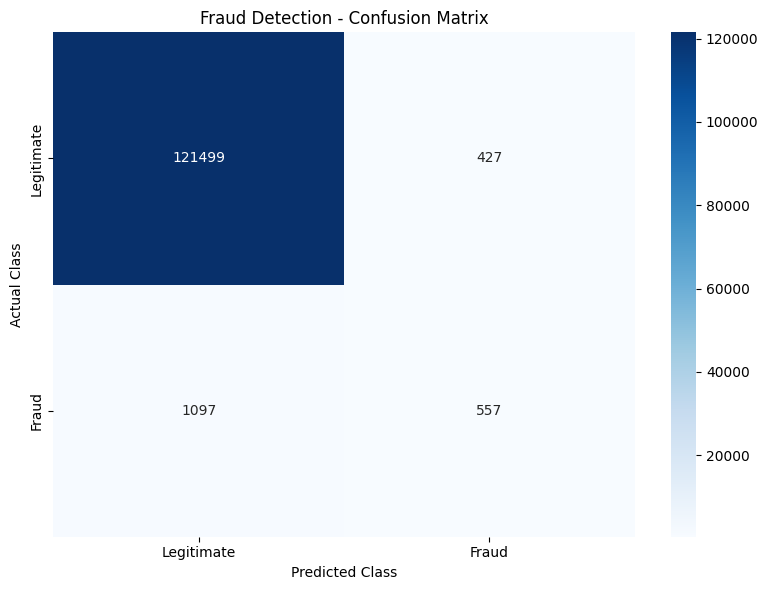

In [31]:
# Visualize the final confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Fraud Detection - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

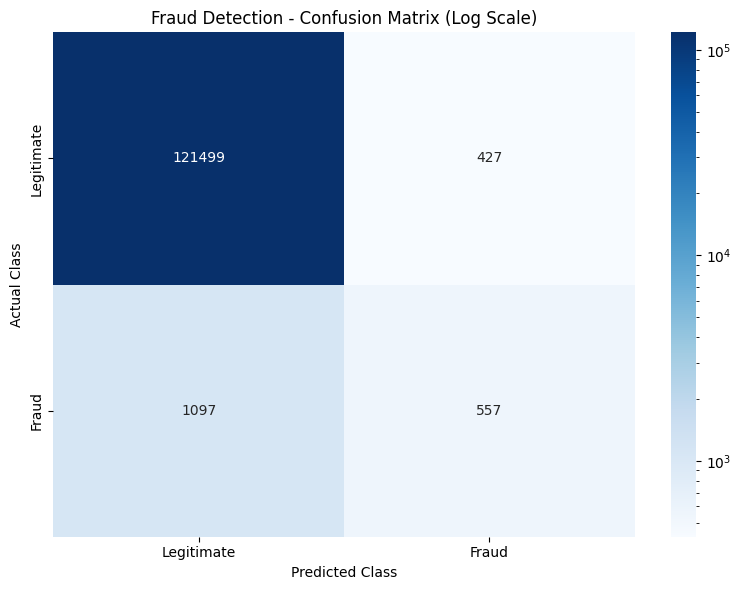

In [32]:
# Import logarithmic color normalization
from matplotlib.colors import LogNorm

# Visualize the confusion matrix using a logarithmic scale
plt.figure(figsize=(8, 6))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    norm=LogNorm(),
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Fraud Detection - Confusion Matrix (Log Scale)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

In [33]:
# Extract logistic regression coefficients
coefficients = pd.DataFrame({
    "Feature": X_model_train_scaled.columns,
    "Coefficient": validation_model.coef_[0]
})

# Sort features by coefficient value
coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
)

# Display model coefficients
coefficients

,Feature,Coefficient
8,type_TRANSFER,147.906067
5,type_CASH_OUT,146.114479
2,oldbalanceOrg,34.914160
0,step,0.006343
3,oldbalanceDest,-0.382950
1,amount,-4.216913
6,type_DEBIT,-14.950903
7,type_PAYMENT,-195.209880
4,type_CASH_IN,-221.377916


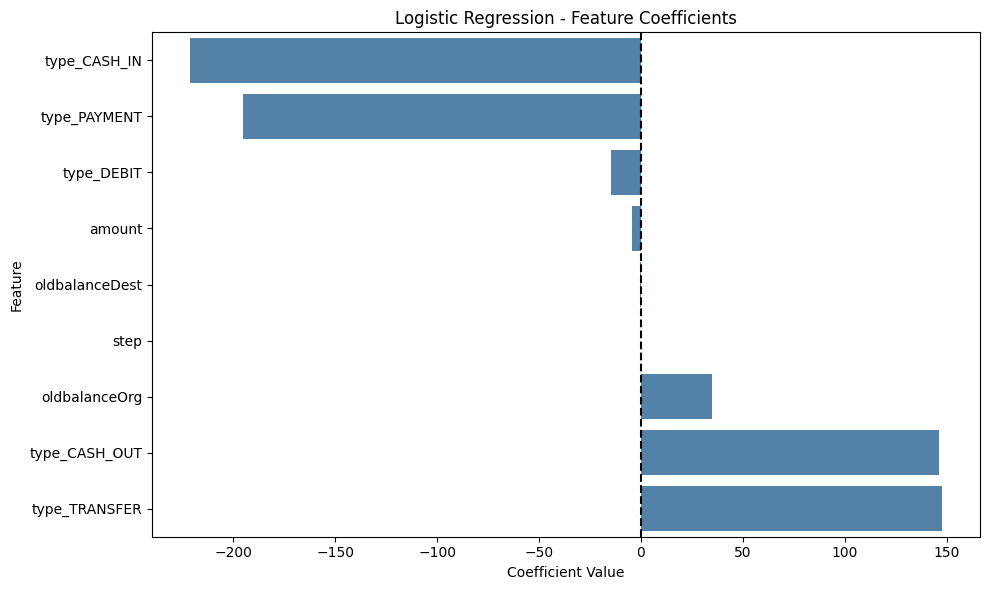

In [34]:
# Sort coefficients for visualization
coefficients_plot = coefficients.sort_values("Coefficient")

# Plot logistic regression coefficients
plt.figure(figsize=(10, 6))

sns.barplot(
    data=coefficients_plot,
    x="Coefficient",
    y="Feature",
    color="steelblue"
)

# Add a reference line at zero
plt.axvline(0, color="black", linestyle="--")

plt.title("Logistic Regression - Feature Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Logistic Regression Coefficient Analysis

The logistic regression coefficients provide insights into how individual features contribute to the model's fraud classification scores.

Transaction types `TRANSFER` and `CASH_OUT` have strongly positive coefficients, while `CASH_IN` and `PAYMENT` have strongly negative coefficients.

The sender's initial balance (`oldbalanceOrg`) also has a positive coefficient, suggesting that higher initial balances are associated with higher fraud scores when other features remain constant.

However, coefficient magnitudes should be interpreted cautiously because numerical features were standardized while categorical features were one-hot encoded.

Additionally, all transaction-type dummy variables were retained, making their individual coefficients dependent on the model's parameterization.

Therefore, these coefficients describe the fitted model's behavior rather than establishing causal relationships or definitive feature importance.

In [35]:
# Import permutation importance
from sklearn.inspection import permutation_importance

# Calculate permutation importance on validation data
permutation_results = permutation_importance(
    validation_model,
    X_validation_scaled,
    y_validation,
    scoring="f1",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

# Create a feature importance table
permutation_df = pd.DataFrame({
    "Feature": X_validation_scaled.columns,
    "Importance": permutation_results.importances_mean
})

# Sort features by importance
permutation_df = permutation_df.sort_values(
    "Importance",
    ascending=False
)

permutation_df

,Feature,Importance
2,oldbalanceOrg,0.103637
8,type_TRANSFER,0.059575
1,amount,0.059083
5,type_CASH_OUT,0.025969
4,type_CASH_IN,0.007123
3,oldbalanceDest,0.003259
7,type_PAYMENT,0.001703
0,step,0.000073
6,type_DEBIT,-0.000156


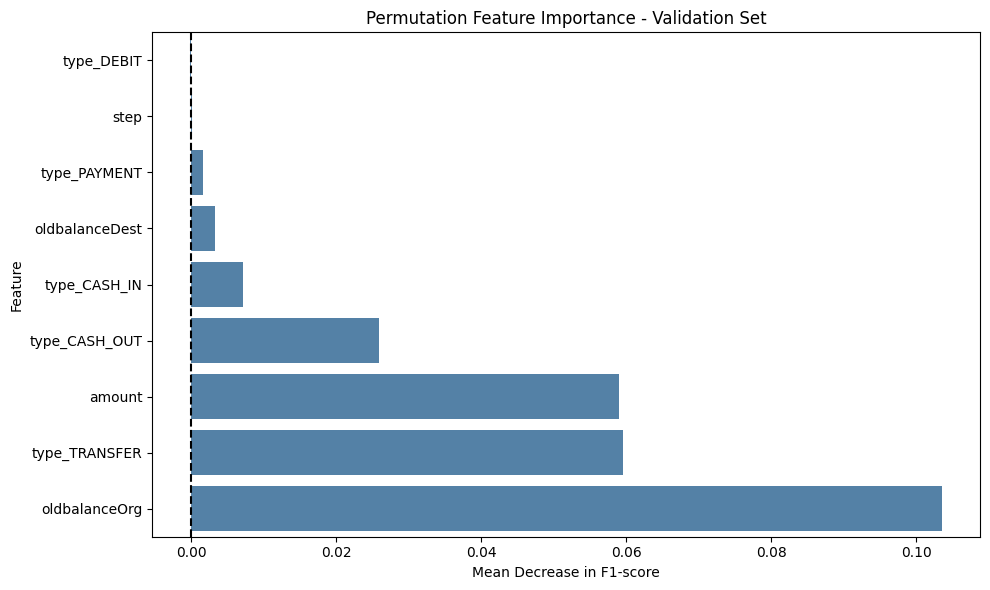

In [36]:
# Sort permutation importance values for visualization
permutation_plot = permutation_df.sort_values("Importance")

# Plot permutation feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=permutation_plot,
    x="Importance",
    y="Feature",
    color="steelblue"
)

# Add a reference line at zero
plt.axvline(0, color="black", linestyle="--")

plt.title("Permutation Feature Importance - Validation Set")
plt.xlabel("Mean Decrease in F1-score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Permutation Feature Importance

Permutation feature importance was calculated on the validation dataset to assess how much the model's predictive performance depends on each feature.

The analysis identified three particularly influential features:

- **oldbalanceOrg:** highest importance, with an average F1-score decrease of approximately 0.104.
- **type_TRANSFER:** average F1-score decrease of approximately 0.060.
- **amount:** average F1-score decrease of approximately 0.059.

The results suggest that the sender's initial balance, transaction type, and transaction amount play important roles in fraud detection.

The `step` and `type_DEBIT` features showed negligible importance under this evaluation procedure.

**Methodological limitations:** Permutation importance was calculated using the model's default classification threshold of 0.5 rather than the selected threshold of 0.9965. Additionally, transaction-type dummy variables were permuted independently, potentially creating invalid category combinations. Therefore, the results should be interpreted as an exploratory assessment of feature importance.

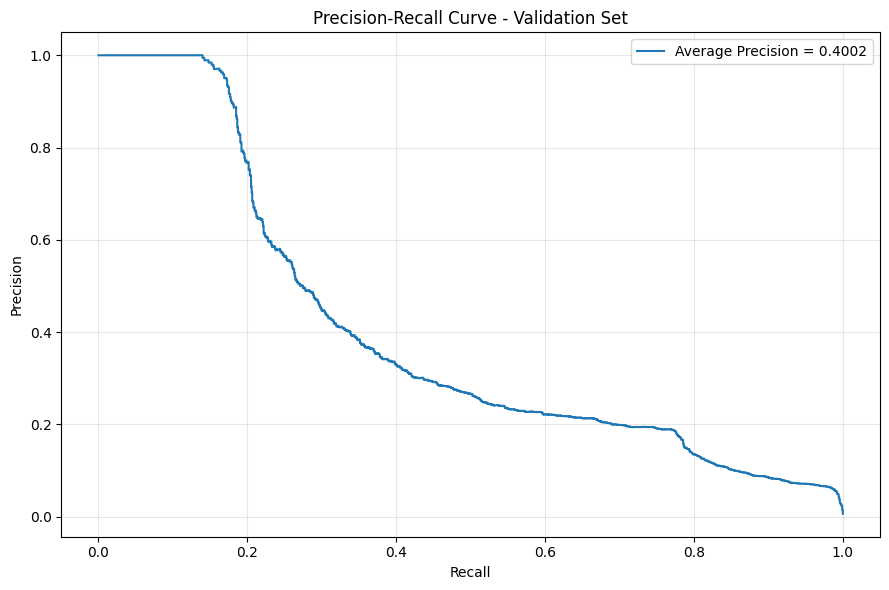

In [37]:
# Import precision-recall evaluation tools
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate precision and recall across classification thresholds
precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_validation,
    y_validation_proba
)

# Calculate average precision on the validation dataset
average_precision = average_precision_score(
    y_validation,
    y_validation_proba
)

# Plot the precision-recall curve
plt.figure(figsize=(9, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {average_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Validation Set")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Precision-Recall Curve Analysis

The Precision-Recall Curve was calculated on the validation dataset to evaluate fraud detection performance across different classification thresholds.

The model achieved an **Average Precision (AP) of 0.4002**.

This result indicates that the model provides substantially better fraud ranking performance than a random classifier, given the low prevalence of fraudulent transactions.

The curve highlights a clear trade-off between precision and recall. High precision can be achieved when identifying a relatively small proportion of fraudulent transactions, but precision decreases as the model attempts to detect more fraud cases.

These findings emphasize the importance of selecting a classification threshold based on operational requirements, including the costs of false positives and undetected fraud.

Average Precision summarizes performance across thresholds and should not be confused with precision at the selected classification threshold.

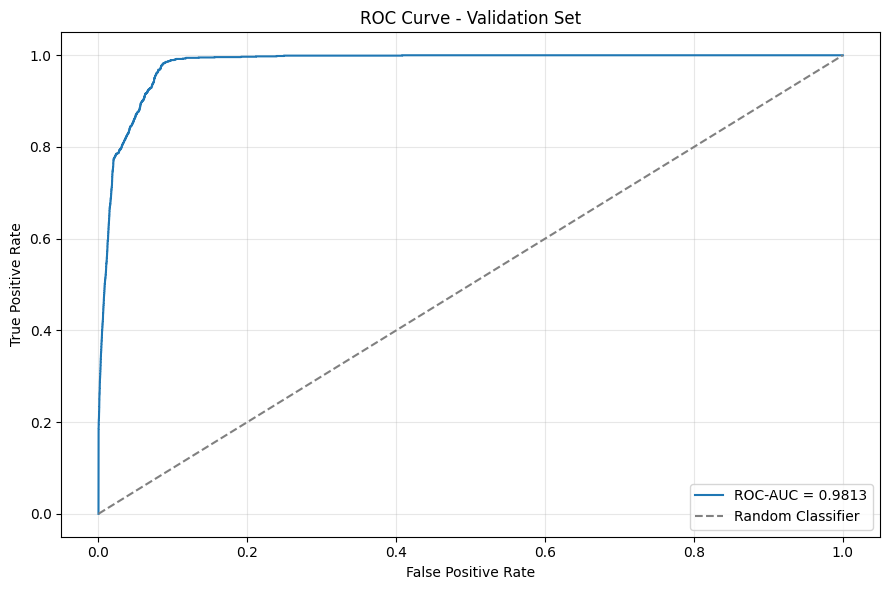

In [38]:
# Import ROC evaluation metrics
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve values on validation data
fpr, tpr, roc_thresholds = roc_curve(
    y_validation,
    y_validation_proba
)

# Calculate the area under the ROC curve
roc_auc = roc_auc_score(
    y_validation,
    y_validation_proba
)

# Plot the ROC curve
plt.figure(figsize=(9, 6))

plt.plot(
    fpr,
    tpr,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

# Add the random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Validation Set")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve was calculated on the validation dataset to evaluate the model's ability to distinguish fraudulent from legitimate transactions across different classification thresholds.

The logistic regression model achieved a **ROC-AUC of 0.9813**.

This indicates excellent discrimination between fraudulent and legitimate transactions, substantially outperforming a random classifier (ROC-AUC = 0.5).

However, ROC-AUC should be interpreted alongside Precision-Recall metrics because the dataset is highly imbalanced.

Despite the high ROC-AUC, the model achieved a fraud recall of only 33.68% on the test dataset at the selected classification threshold of 0.9965.

This highlights the distinction between overall ranking performance and operational classification performance at a specific threshold.

In [39]:
# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully.")

Random Forest imported successfully.


In [40]:
# Initialize the Random Forest classifier
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=15,
    min_samples_leaf=10,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model initialized.")

Random Forest model initialized.


In [41]:
# Train the Random Forest on the training dataset
rf_model.fit(
    X_model_train_encoded,
    y_model_train
)

print("Random Forest training completed.")

Random Forest training completed.


In [42]:
# Predict fraud probabilities on the validation dataset
rf_validation_proba = rf_model.predict_proba(
    X_validation_encoded
)[:, 1]

# Display the first ten fraud scores
pd.DataFrame({
    "Actual Fraud": y_validation.iloc[:10].to_numpy(),
    "Fraud Score": rf_validation_proba[:10]
})

,Actual Fraud,Fraud Score
0,0,0.000000
1,0,0.152308
2,0,0.058648
3,0,0.018916
4,0,0.000000
5,0,0.018916
6,0,0.018916
7,0,0.018916
8,0,0.000476
9,0,0.018916


In [43]:
# Calculate Average Precision for Random Forest
rf_average_precision = average_precision_score(
    y_validation,
    rf_validation_proba
)

# Compare Random Forest and Logistic Regression
print(f"Logistic Regression AP: {average_precision:.4f}")
print(f"Random Forest AP:       {rf_average_precision:.4f}")

Logistic Regression AP: 0.4002
Random Forest AP:       0.8582


In [44]:
# Calculate precision and recall for Random Forest
rf_precision, rf_recall, rf_thresholds = precision_recall_curve(
    y_validation,
    rf_validation_proba
)

# Calculate F1-score for each available threshold
rf_f1_scores = (
    2 * rf_precision[:-1] * rf_recall[:-1]
    / (rf_precision[:-1] + rf_recall[:-1] + 1e-12)
)

# Select the threshold with the highest F1-score
rf_best_index = np.argmax(rf_f1_scores)
rf_best_threshold = rf_thresholds[rf_best_index]

print(f"Best threshold: {rf_best_threshold:.4f}")
print(f"Validation precision: {rf_precision[rf_best_index]:.4f}")
print(f"Validation recall: {rf_recall[rf_best_index]:.4f}")
print(f"Validation F1-score: {rf_f1_scores[rf_best_index]:.4f}")

Best threshold: 0.8701
Validation precision: 0.9383
Validation recall: 0.7331
Validation F1-score: 0.8231


In [45]:
# Predict fraud scores on the test dataset
rf_test_proba = rf_model.predict_proba(
    X_final_test_encoded
)[:, 1]

# Apply the threshold selected on validation data
rf_test_pred = (
    rf_test_proba >= rf_best_threshold
).astype(int)

# Display the classification report
print(classification_report(
    y_test,
    rf_test_pred,
    target_names=["Legitimate", "Fraud"],
    digits=4
))

              precision    recall  f1-score   support

  Legitimate     0.9961    0.9997    0.9979    121926
       Fraud     0.9671    0.7098    0.8187      1654

    accuracy                         0.9958    123580
   macro avg     0.9816    0.8547    0.9083    123580
weighted avg     0.9957    0.9958    0.9955    123580



In [46]:
# Calculate the Random Forest confusion matrix
rf_test_cm = confusion_matrix(
    y_test,
    rf_test_pred
)

# Display the confusion matrix
print("Random Forest Confusion Matrix:")
print(rf_test_cm)

Random Forest Confusion Matrix:
[[121886     40]
 [   480   1174]]


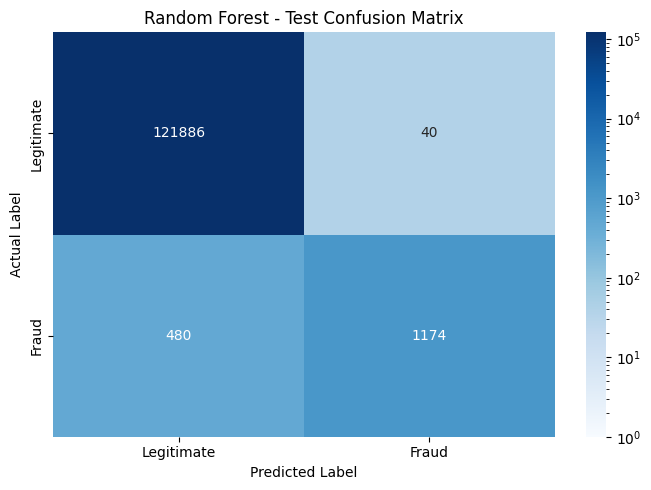

In [47]:
# Plot Random Forest confusion matrix with logarithmic colors
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    norm=LogNorm(vmin=1, vmax=rf_test_cm.max()),
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Random Forest - Test Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [48]:
# Extract Random Forest feature importance
rf_importance = pd.DataFrame({
    "Feature": X_model_train_encoded.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print(rf_importance.to_string(index=False))

       Feature  Importance
 oldbalanceOrg    0.314586
        amount    0.241365
 type_TRANSFER    0.100147
  type_PAYMENT    0.095180
  type_CASH_IN    0.094828
oldbalanceDest    0.066948
 type_CASH_OUT    0.063324
          step    0.022807
    type_DEBIT    0.000816


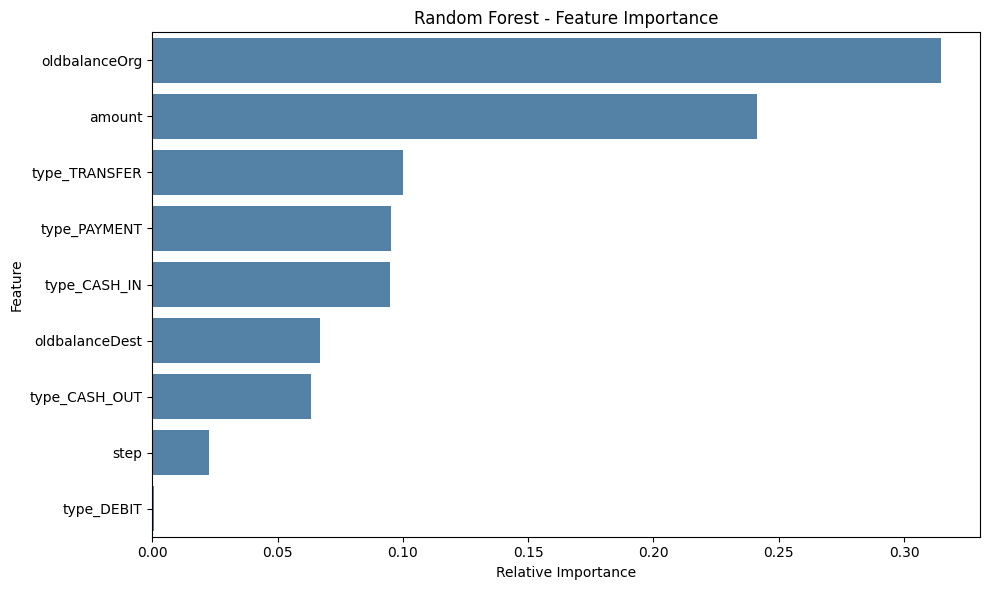

In [49]:
# Plot Random Forest feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Random Forest – Model Evaluation and Feature Importance

A Random Forest classifier was trained using 50 decision trees, a maximum depth of 15, and balanced subsample class weights.

**Validation results:**
- Average Precision: 0.8582
- Optimal F1 threshold: 0.8701
- Precision: 0.9383
- Recall: 0.7331
- F1-score: 0.8231

**Test results:**
- Precision: 0.9671
- Recall: 0.7098
- F1-score: 0.8187
- Accuracy: 0.9958

The test confusion matrix shows 1,174 correctly detected fraudulent transactions, 480 missed frauds, and only 40 false alarms.

The Random Forest substantially outperformed Logistic Regression on the evaluation metrics.

**Feature importance analysis**

The most influential features were:

- `oldbalanceOrg` (31.46%)
- `amount` (24.14%)
- `type_TRANSFER` (10.01%)

These importance values represent relative contributions to impurity reduction across the decision trees. They do not indicate causal effects.

**Limitations**

The analysis uses synthetic PaySim transaction data. The final test period had also been examined during preliminary experiments, so the reported test results should be interpreted as exploratory rather than as an entirely untouched holdout evaluation.

In [50]:
# Compare model performance on the test dataset
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [0.5661, 0.9671],
    "Recall": [0.3368, 0.7098],
    "F1-score": [0.4223, 0.8187],
    "Accuracy": [0.9877, 0.9958]
})

# Display the comparison table
model_comparison

,Model,Precision,Recall,F1-score,Accuracy
0,Logistic Regression,0.5661,0.3368,0.4223,0.9877
1,Random Forest,0.9671,0.7098,0.8187,0.9958


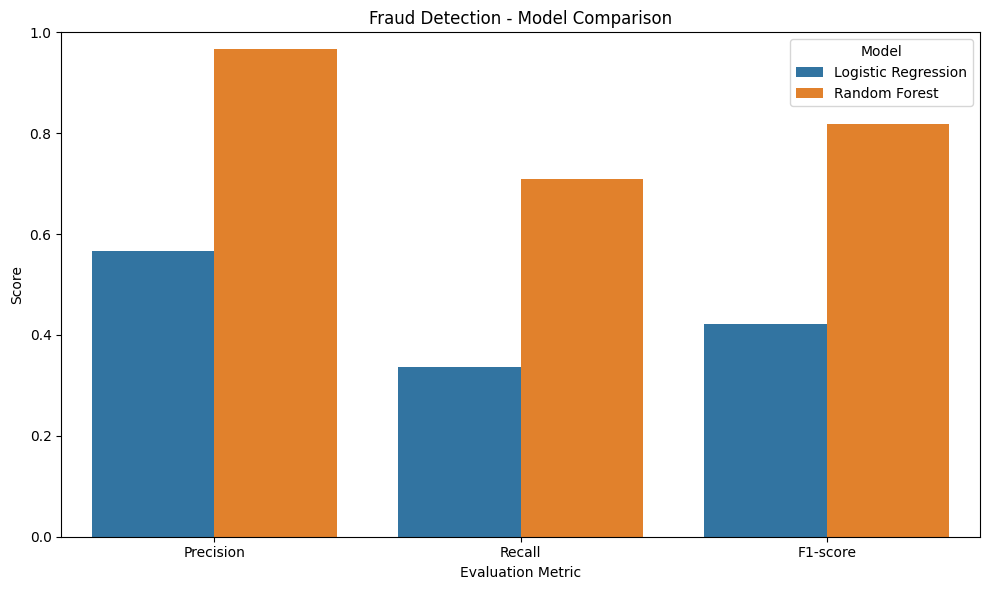

In [51]:
# Reshape the comparison table for visualization
comparison_plot = model_comparison.melt(
    id_vars="Model",
    value_vars=["Precision", "Recall", "F1-score"],
    var_name="Metric",
    value_name="Score"
)

# Plot model performance comparison
plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Fraud Detection - Model Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

### Final Model Comparison

Two classification algorithms were evaluated for financial fraud detection: Logistic Regression and Random Forest.

Both models were evaluated on the same chronological test dataset, using classification thresholds selected on the validation dataset.

**Test-set performance:**

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Precision (Fraud) | 0.5661 | 0.9671 |
| Recall (Fraud) | 0.3368 | 0.7098 |
| F1-score (Fraud) | 0.4223 | 0.8187 |
| Accuracy | 0.9877 | 0.9958 |

**Conclusion**

Random Forest achieved substantially better fraud detection performance than Logistic Regression, with higher precision, recall, and F1-score.

The model correctly identified 1,174 of 1,654 fraudulent transactions, while generating only 40 false positives.

Random Forest was therefore selected as the best-performing model in this experiment.

**Limitations**

These results were obtained using the synthetic PaySim dataset and should not be interpreted as guaranteed performance on real financial transactions.

Furthermore, the test period had been examined during preliminary experiments, so an independent, previously